# ISIC 2019 — giai đoạn 1: xem ảnh và ghi chú

**Không train, không cần GPU.** Chỉ gắn cùng dataset ảnh ISIC 2019 vào Kaggle Input. Notebook đã nhúng manifest đúng split và dự đoán validation ResNet18 1/n; không cần gắn checkpoint hoặc Output cũ.

Đọc tài liệu `KIEN_THUC_8_LOP.md` cùng notebook. Đây là công cụ quan sát, không chẩn đoán/đổi nhãn.

1. Chạy cell 1–5. Chọn tập/lớp/trang, bấm **Hiện trang**, copy ID rồi **Mở ảnh gốc**.
2. Ghi điều thấy ở `observations`, suy đoán riêng ở `hypothesis`, câu hỏi chuyên môn ở `expert_question`. Bấm **Lưu ghi chú**. Chỉ `reviewed`/`needs_expert` được tính đã xem; ảnh cần chuyên gia vẫn là vấn đề chưa giải quyết.
3. Chạy cell 7 sau mỗi phiên để xuất ZIP. Tải ZIP và `review_log.csv` trước khi kết thúc kernel. Save Version không thay thế sao lưu các tương tác; Save & Run All có thể bắt đầu phiên sạch.
4. Phiên sau gắn log đã tải làm Input, đặt `RESUME_REVIEW` và tùy chọn `RESUME_EVENTS` ở cell 1. Không nối log từ split khác.

Mặc định chỉ **20.242 ảnh train+val**; test nội bộ 5.085 ảnh bị khóa. Bốn ảnh mâu thuẫn nhãn đã loại không thuộc catalogue. Sau khi chốt phương pháp mới được mở test bằng cờ và ghi chú chốt; việc này không biến test từng xem thành test mù mới. Giữ OUT riêng nếu mở test.

Nhãn và dự đoán mặc định ẩn để giảm thiên kiến; chọn một lớp/nhóm lỗi vẫn tiết lộ thông tin, vì vậy nên xem thêm mẫu ngẫu nhiên ALL trước. `typical_candidate` chỉ là nhận xét người xem, không do model tự xác nhận. Không suy Fitzpatrick/chủng tộc từ màu ảnh; không suy kích thước mm từ pixel thiếu thước chuẩn.


## 1. Cấu hình

In [10]:
from pathlib import Path
# C?u h?nh ???ng d?n ch?y local tr?n Windows
ROOT = Path(r"D:\ISIC2019_Review\input")
OUT = Path(r"D:\ISIC2019_Review\output")
IMAGE_ROOT = r"D:\ISIC2019_Review\input\isic_images"
RESUME_REVIEW = ''  # ???ng d?n review_log.csv n?u ?? c? t? tr??c; ?? tr?ng n?u ch?a c?
RESUME_EVENTS = ''  # ???ng d?n review_events.jsonl n?u mu?n n?i ??y ?? l?ch s? m? ?nh
REVIEWER = 'Nguyen Tuan Duc'
PREDICTIONS_CSV = ''  # t?y ch?n: file val predictions kh?c; ?? tr?ng d?ng ResNet18 1/n ?? x?c nh?n
PREDICTION_RUN = 'ResNet18_1n_20260927_180839_430979'  # s?a ??ng t?n n?u d?ng predictions kh?c
INCLUDE_TEST = False
METHOD_FROZEN_NOTE = ''  # ch? m? test sau khi ch?t ph??ng ph?p: ghi ng?y, phi?n b?n, l? do
RUN_QUALITY_SCAN = False  # True: qu?t k?ch th??c/ch? s? ch?t l??ng tr?n t?p ?ang ???c ph?p xem
PAGE_SIZE = 12


## 2. Manifest, nguồn ảnh và dự đoán đã xác nhận

In [11]:
import io, os, json, hashlib, base64, zlib, math, shutil
from datetime import datetime, timezone
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML, FileLink, clear_output
LABELS = ['MEL','NV','BCC','AK','BKL','DF','VASC','SCC']
EXPECTED = {'train':'8b20d34a2ce7d0d0f082bb18a394b3bc8ec6a77cee7e5407581d4a901c418dc7',
'val':'78228795abe3580aab1b5993f631eb4990944fdf36e42a61ed7c9630ab728bf1',
'test':'998a6ae29bc3e2eacdcb0670b9f81c38ef894a9fca0fbbc7ca231ce59a9f7262'}
def unpack(payload):
    return pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(payload))), keep_default_na=False)
def fingerprint(d):
    rows=d[['image','label_name','file_sha256']].sort_values('image')
    return hashlib.sha256('\n'.join('|'.join(map(str,x)) for x in rows.itertuples(index=False,name=None)).encode()).hexdigest()
DEV_PAYLOAD = '...'
TEST_PAYLOAD_SEALED = '...'
PRED_PAYLOAD = '...'
catalog = unpack(DEV_PAYLOAD)
if INCLUDE_TEST:
    if len(METHOD_FROZEN_NOTE.strip()) < 15:
        raise ValueError('Cần ghi ngày/phiên bản chốt phương pháp trước khi mở test. Test đã từng xem, không thành test mù mới.')
    catalog=pd.concat([catalog,unpack(TEST_PAYLOAD_SEALED)],ignore_index=True)
assert catalog.image.is_unique
for split,part in catalog.groupby('split'):
    assert fingerprint(part)==EXPECTED[split],f'Manifest {split} không khớp'
for a in catalog.split.unique():
    for b in catalog.split.unique():
        if a<b:
            for col in ['image','group','file_sha256']:
                assert set(catalog.loc[catalog.split==a,col]).isdisjoint(catalog.loc[catalog.split==b,col])
OUT.mkdir(parents=True,exist_ok=True)
# Chỉ index đường dẫn trong dataset gốc; không tải ảnh test khi đang khóa.
if IMAGE_ROOT:
    data_root=Path(IMAGE_ROOT)
else:
    found=list(ROOT.rglob('ISIC_2019_Training_GroundTruth.csv'))
    if len(found)!=1:
        raise RuntimeError(f'Cần đúng 1 CSV GroundTruth, thấy {len(found)}. Gỡ Input dư hoặc đặt IMAGE_ROOT.')
    data_root=found[0].parent
wanted=set(catalog.image); paths={}
for path in data_root.rglob('*'):
    if path.suffix.lower() in {'.jpg','.jpeg','.png'} and path.stem in wanted:
        if path.stem in paths:raise RuntimeError(f'Trùng ID đường dẫn {path.stem}; chọn đúng dataset.')
        paths[path.stem]=str(path)
catalog['path']=catalog.image.map(paths)
if catalog.path.isna().any():
    raise RuntimeError(f'Thiếu {int(catalog.path.isna().sum())} ảnh. Ví dụ '+str(catalog.loc[catalog.path.isna(),'image'].head().tolist()))
catalog=catalog.set_index('image',drop=False)
def validate_predictions(p):
    required={'image','true_label','pred_label'}
    if not required.issubset(p):raise ValueError('Predictions cần image,true_label,pred_label.')
    if not p.image.is_unique:raise ValueError('Predictions trùng image ID.')
    val_ids=set(catalog.loc[catalog.split=='val','image'])
    if not set(p.image).issubset(val_ids):raise ValueError('Chỉ chấp nhận predictions validation của manifest này.')
    truth=catalog.loc[p.image,'label_name'].to_numpy()
    if not np.array_equal(p.true_label.to_numpy(),truth):raise ValueError('Nhãn predictions khác manifest.')
    if not p.pred_label.isin(LABELS).all():raise ValueError('Predicted label không hợp lệ.')
    if 'file_sha256' in p and not np.array_equal(p.file_sha256.to_numpy(),catalog.loc[p.image,'file_sha256'].to_numpy()):
        raise ValueError('Hash predictions khác manifest.')
    return p
predictions=validate_predictions(pd.read_csv(PREDICTIONS_CSV) if PREDICTIONS_CSV else unpack(PRED_PAYLOAD))
for col in ['pred_label','max_softmax']:
    catalog[col]=catalog.image.map(predictions.set_index('image')[col]) if col in predictions else np.nan
catalog['prediction_run']=np.where(catalog.pred_label.notna(),PREDICTION_RUN,'')
print('Tập được phép xem:',catalog.groupby('split').size().to_dict())
print('Predictions:',PREDICTION_RUN,len(predictions),'ảnh validation. Chưa có dự đoán train trong công cụ này.')
print('Không có ảnh nào được tự đánh dấu đã xem.')


Tập được phép xem: {'train': 15140, 'val': 5102}
Predictions: ResNet18_1n_20260927_180839_430979 5102 ảnh validation. Chưa có dự đoán train trong công cụ này.
Không có ảnh nào được tự đánh dấu đã xem.


## 3. Lưu ghi chú và công cụ quan sát

In [12]:
# Cell 3: nhật ký, mở ảnh, contact sheet và đo tiến độ
SCHEMA='isic_review_v1'
TAG_FIELDS=['hair','ruler','black_border','ink_or_text','blur','glare','uneven_light','edge_cut']
NOTE_FIELDS=TAG_FIELDS+['apparent_skin_color','lesion_fraction','morphology','colors','border','structures','typicality','observations','hypothesis','expert_question']
BASE_COLS=['schema','image','split','label_name','file_sha256','status','reviewer','updated_utc','prediction_run']
REVIEW_COLS=BASE_COLS+NOTE_FIELDS
LOG=OUT/'review_log.csv'; EVENTS=OUT/'review_events.jsonl'
opened_session=set()
def utc():return datetime.now(timezone.utc).isoformat()
def atomic_csv(d,path):
    temp=path.with_suffix(path.suffix+'.tmp');d.to_csv(temp,index=False,encoding='utf-8-sig');os.replace(temp,path)
def load_review(path):
    d=pd.read_csv(path,keep_default_na=False)
    if not set(REVIEW_COLS).issubset(d.columns):raise ValueError('Review log sai schema; dùng file review_log.csv của công cụ này.')
    if not d.image.is_unique:raise ValueError('Review log trùng ID.')
    if len(d) and (not d.schema.eq(SCHEMA).all() or not d.status.isin(['draft','reviewed','needs_expert']).all()):raise ValueError('Schema/status sai.')
    # Không cho nhập log test vào phiên development.
    if not set(d.image).issubset(set(catalog.image)):raise ValueError('Log chứa ID ngoài tập đang mở (có thể có test).')
    ref=catalog.loc[d.image]
    for c in ['split','label_name','file_sha256']:
        if not np.array_equal(d[c].to_numpy(),ref[c].to_numpy()):raise ValueError(f'Log khác manifest: {c}')
    return d[REVIEW_COLS]
if LOG.exists() and RESUME_REVIEW and Path(RESUME_REVIEW).resolve()!=LOG.resolve():
    raise ValueError('Đã có log trong OUT. Chọn OUT mới hoặc bỏ RESUME_REVIEW; không ghi đè âm thầm.')
review=load_review(LOG) if LOG.exists() else (load_review(RESUME_REVIEW) if RESUME_REVIEW else pd.DataFrame(columns=REVIEW_COLS))
atomic_csv(review,LOG)
if RESUME_EVENTS and not EVENTS.exists():
    # Kiểm tra từng sự kiện trước khi nối, giữ nguyên dữ liệu lịch sử.
    lines=Path(RESUME_EVENTS).read_text().splitlines()
    for line in lines:
        e=json.loads(line)
        if e.get('image') and e['image'] not in catalog.index:raise ValueError('Events có ID ngoài phiên.')
    EVENTS.write_text('\n'.join(lines)+'\n')
def event(kind,image_id='',**extra):
    e={'utc':utc(),'event':kind,'image':image_id,'reviewer':REVIEWER,**extra}
    with EVENTS.open('a',encoding='utf-8') as f:f.write(json.dumps(e,ensure_ascii=False)+'\n')
if INCLUDE_TEST:event('test_unlocked',note=METHOD_FROZEN_NOTE)
def require_image(image_id):
    if image_id not in catalog.index:raise ValueError('ID không có trong tập đang mở; test bị khóa mặc định.')
    return catalog.loc[image_id]
@lru_cache(maxsize=2048)
def checked_path(image_id):
    row=require_image(image_id);p=Path(row.path)
    h=hashlib.sha256()
    with p.open('rb') as f:
        for b in iter(lambda:f.read(1048576),b''):h.update(b)
    if h.hexdigest()!=row.file_sha256:raise ValueError('Byte ảnh không đúng manifest: '+image_id)
    return p
@lru_cache(maxsize=256)
def thumb(image_id):
    with Image.open(checked_path(image_id)) as im:
        rgb=im.convert('RGB');rgb.thumbnail((440,360));return rgb.copy()
def open_original(image_id, show_label=False, show_prediction=False):
    import html
    row=require_image(image_id);p=checked_path(image_id)
    with Image.open(p) as im:w,h=im.size
    print(image_id, '| split:',row['split'],'| kích thước:',w,'x',h)
    if show_label:print('Nhãn dataset:',row.label_name)
    if show_prediction:print('Dự đoán:',row.pred_label,'| nguồn:',row.prediction_run)
    mime='image/png' if p.suffix.lower()=='.png' else 'image/jpeg'
    raw=base64.b64encode(p.read_bytes()).decode()
    display(HTML(f'<div style="overflow:auto;max-height:650px;border:1px solid #aaa"><img src="data:{mime};base64,{raw}" style="max-width:none;width:{w}px;height:{h}px" alt="{html.escape(image_id)}"></div>'))
    opened_session.add(image_id);event('original_opened',image_id)
    # Bản sao nguyên byte để tải xuống. Không nén/resize ảnh gốc.
    d=OUT/'opened_originals';d.mkdir(exist_ok=True);dest=d/p.name
    # Chỉ giữ bản sao ảnh đang mở để không nhân đôi cả dataset trong Kaggle working.
    for old_file in d.iterdir():
        if old_file.is_file() and old_file!=dest:old_file.unlink()
    if not dest.exists():shutil.copyfile(p,dest)
    display(FileLink(str(dest),result_html_prefix='Tải ảnh nguyên byte: '))
    return {'width':w,'height':h}
def select_images(split='val',label='ALL',mode='all',pair='ALL',order='id'):
    if split not in catalog.split.unique():raise ValueError('Split đang khóa/không tồn tại.')
    d=catalog[catalog.split==split].copy();d.index.name='_image_index'
    if label!='ALL':d=d[d.label_name==label]
    completed=set(review.loc[review.status.isin(['reviewed','needs_expert']),'image'])
    if mode=='unreviewed':d=d[~d.image.isin(completed)]
    elif mode=='reviewed':d=d[d.image.isin(completed)]
    elif mode=='errors':d=d[d.pred_label.notna() & d.pred_label.ne(d.label_name)]
    elif mode=='correct':d=d[d.pred_label.notna() & d.pred_label.eq(d.label_name)]
    elif mode in ['typical_candidate','atypical_candidate']:
        d=d[d.image.isin(review.loc[review.typicality==mode,'image'])]
    if pair!='ALL':
        a,b=pair.split('-');d=d[((d.label_name==a)&(d.pred_label==b))|((d.label_name==b)&(d.pred_label==a))]
    if order=='random':return d.sample(frac=1,random_state=42)
    if order=='low_resolution':
        q=load_quality()
        if q.empty:raise ValueError('Chạy scan_quality() trước khi xếp theo kích thước.')
        d['min_side']=d.image.map(q.set_index('image').min_side)
        return d.sort_values(['min_side','image'],na_position='last')
    return d.sort_index()
def contact_sheet(split='val',label='ALL',page=1,mode='all',pair='ALL',order='id',show_label=False,show_prediction=False,save=False):
    d=select_images(split,label,mode,pair,order);pages=max(1,math.ceil(len(d)/PAGE_SIZE))
    page=max(1,min(int(page),pages));batch=d.iloc[(page-1)*PAGE_SIZE:page*PAGE_SIZE]
    print(f'{len(d)} ảnh | trang {page}/{pages}. Hiện trên sheet chưa tính là đã xem.')
    if batch.empty:return []
    cols=4;fig,axes=plt.subplots(math.ceil(len(batch)/cols),cols,figsize=(15,math.ceil(len(batch)/cols)*3.4),squeeze=False)
    for ax in axes.flat:ax.axis('off')
    for ax,(iid,row) in zip(axes.flat,batch.iterrows()):
        ax.imshow(thumb(iid));title=iid
        if show_label:title+='\nDataset: '+row.label_name
        if show_prediction and pd.notna(row.pred_label):title+='\nPred: '+row.pred_label
        ax.set_title(title,fontsize=8);event('thumbnail_displayed',iid,page=page,split=split)
    plt.tight_layout()
    if save:
        p=OUT/f'sheet_{split}_{label}_{mode}_{pair}_{order}_{page:04d}.png';fig.savefig(p,dpi=150);print('Đã xuất',p)
    plt.show();plt.close(fig)
    return batch.image.tolist()
def save_review(image_id,status='draft',**notes):
    global review
    row=require_image(image_id)
    if status not in ['draft','reviewed','needs_expert']:raise ValueError('Status không hợp lệ.')
    if status!='draft' and image_id not in opened_session:raise ValueError('Hãy mở ảnh gốc trong phiên này trước khi đánh dấu đã xem.')
    if set(notes)-set(NOTE_FIELDS):raise ValueError('Tên cột ghi chú không hợp lệ.')
    old=review.loc[review.image==image_id]
    rec=old.iloc[0].to_dict() if len(old) else {k:'' for k in REVIEW_COLS}
    rec.update(notes)
    for k in TAG_FIELDS:
        if rec[k] not in ['', 'unknown','absent','present']:raise ValueError('Tag phải unknown/absent/present.')
    if status!='draft' and not str(rec['observations']).strip():raise ValueError('Cần ghi quan sát trực tiếp; không chỉ tick hoàn thành.')
    rec.update(schema=SCHEMA,image=image_id,split=row['split'],label_name=row.label_name,file_sha256=row.file_sha256,status=status,reviewer=REVIEWER,updated_utc=utc(),prediction_run=row.prediction_run)
    review=pd.concat([review[review.image!=image_id],pd.DataFrame([rec])],ignore_index=True)
    atomic_csv(review[REVIEW_COLS],LOG);event('review_saved',image_id,status=status,record=rec)
    print('Đã lưu',image_id,status)
def progress():
    d=catalog[['image','split','label_name']].copy()
    d['reviewed']=d.image.isin(review.loc[review.status.isin(['reviewed','needs_expert']),'image'])
    d['needs_expert']=d.image.isin(review.loc[review.status=='needs_expert','image'])
    t=d.groupby(['split','label_name']).agg(total=('image','size'),reviewed=('reviewed','sum'),needs_expert=('needs_expert','sum')).reset_index()
    t['remaining']=t.total-t.reviewed;t['percent_reviewed']=100*t.reviewed/t.total
    atomic_csv(t,OUT/'coverage.csv');display(t);return t
def load_quality():
    p=OUT/'quality_scan.csv'
    if not p.exists():return pd.DataFrame()
    q=pd.read_csv(p,keep_default_na=False)
    if not set(q.image).issubset(catalog.index):raise ValueError('Quality cache chứa tập khác; dùng OUT riêng.')
    return q
def scan_quality():
    # Proxy để xếp hàng xem, KHÔNG tự xác nhận mờ hoặc màu da/Fitzpatrick.
    q=load_quality();done=set(q.image) if len(q) else set();rows=q.to_dict('records') if len(q) else []
    for n,(iid,row) in enumerate(catalog.iterrows()):
        if iid in done:continue
        with Image.open(checked_path(iid)) as im:
            w,h=im.size;x=im.convert('RGB');x.thumbnail((256,256));a=np.asarray(x,dtype=float);g=a.mean(2)
        edge=np.concatenate([g[0],g[-1],g[:,0],g[:,-1]])
        rows.append({'image':iid,'split':row['split'],'file_sha256':row.file_sha256,'width':w,'height':h,'min_side':min(w,h),'aspect_ratio':w/h,
        'dark_edge_fraction':float((edge<20).mean()),'mean_gray':float(g.mean()),'gradient_proxy':float(np.diff(g,axis=0).var()+np.diff(g,axis=1).var())})
        if len(rows)%250==0:
            atomic_csv(pd.DataFrame(rows),OUT/'quality_scan.csv');print('Đã quét',len(rows), '/',len(catalog))
    q=pd.DataFrame(rows);atomic_csv(q,OUT/'quality_scan.csv');return q
# Mẫu trống đúng schema, không chứa nhãn test hay tự điền kết luận.
pd.DataFrame(columns=REVIEW_COLS).to_csv(OUT/'review_template.csv',index=False,encoding='utf-8-sig')
if RUN_QUALITY_SCAN:scan_quality()


## 4. Đối chiếu confusion matrix validation

,true_label,pred_label,count,support,row_rate,prediction_run
7,NV,MEL,316,2614,0.120888,ResNet18_1n_20260927_180839_430979
10,NV,BKL,208,2614,0.079572,ResNet18_1n_20260927_180839_430979
0,MEL,NV,178,927,0.192017,ResNet18_1n_20260927_180839_430979
8,NV,BCC,89,2614,0.034047,ResNet18_1n_20260927_180839_430979
3,MEL,BKL,63,927,0.067961,ResNet18_1n_20260927_180839_430979
28,BKL,MEL,63,513,0.122807,ResNet18_1n_20260927_180839_430979
29,BKL,NV,51,513,0.099415,ResNet18_1n_20260927_180839_430979
1,MEL,BCC,49,927,0.052859,ResNet18_1n_20260927_180839_430979
16,BCC,AK,45,634,0.070978,ResNet18_1n_20260927_180839_430979
17,BCC,BKL,42,634,0.066246,ResNet18_1n_20260927_180839_430979


,true_label,pred_label,count,support,row_rate,prediction_run
7,NV,MEL,316,2614,0.120888,ResNet18_1n_20260927_180839_430979
0,MEL,NV,178,927,0.192017,ResNet18_1n_20260927_180839_430979
17,BCC,BKL,42,634,0.066246,ResNet18_1n_20260927_180839_430979
30,BKL,BCC,33,513,0.064327,ResNet18_1n_20260927_180839_430979


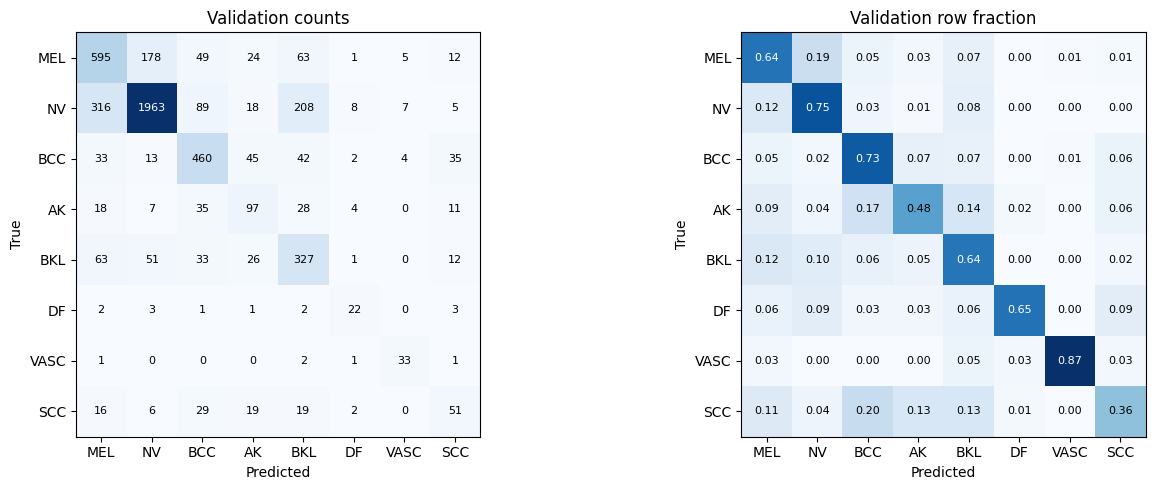

Mẫu này chỉ có ResNet18 1/n khi để PREDICTIONS_CSV trống; không gọi là ensemble.


In [13]:
# Cell 4: confusion matrix chỉ từ predictions validation đã gắn
cm=pd.crosstab(predictions.true_label,predictions.pred_label).reindex(index=LABELS,columns=LABELS,fill_value=0)
cm.to_csv(OUT/'val_confusion_counts.csv')
pair_rows=[]
for a in LABELS:
    for b in LABELS:
        if a!=b:
            total=int(cm.loc[a].sum());count=int(cm.loc[a,b])
            pair_rows.append({'true_label':a,'pred_label':b,'count':count,'support':total,'row_rate':count/total if total else np.nan,'prediction_run':PREDICTION_RUN})
pairs=pd.DataFrame(pair_rows).sort_values('count',ascending=False)
pairs.to_csv(OUT/'val_error_pairs.csv',index=False)
display(pairs.head(10))
display(pairs[((pairs.true_label=='MEL')&(pairs.pred_label=='NV'))|((pairs.true_label=='NV')&(pairs.pred_label=='MEL'))|((pairs.true_label=='BCC')&(pairs.pred_label=='BKL'))|((pairs.true_label=='BKL')&(pairs.pred_label=='BCC'))])
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,arr,title in [(axes[0],cm.values,'Validation counts'),(axes[1],cm.div(cm.sum(axis=1).replace(0,np.nan),axis=0).values,'Validation row fraction')]:
    ax.imshow(arr,cmap='Blues');ax.set_xticks(range(8),LABELS);ax.set_yticks(range(8),LABELS);ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(title)
    for i in range(8):
        for j in range(8):ax.text(j,i,str(int(arr[i,j])) if ax==axes[0] else f'{arr[i,j]:.2f}',ha='center',va='center',fontsize=8,color='white' if arr[i,j]>np.nanmax(arr)*.6 else 'black')
plt.tight_layout();plt.savefig(OUT/'val_confusion_review.png',dpi=150);plt.show();plt.close(fig)
print('Mẫu này chỉ có ResNet18 1/n khi để PREDICTIONS_CSV trống; không gọi là ensemble.')


## 5. Giao diện tương tác

In [14]:
# Cell 5: giao diện duyệt ảnh. Nếu widget không hiển thị, dùng hàm ở cell kế.
try:
    import ipywidgets as W
    import html
    split_w=W.Dropdown(options=list(catalog.split.unique()),value='val',description='Tập')
    class_w=W.Dropdown(options=['ALL']+LABELS,description='Lớp')
    mode_w=W.Dropdown(options=['all','unreviewed','reviewed','errors','correct','typical_candidate','atypical_candidate'],description='Nhóm')
    pair_w=W.Dropdown(options=['ALL','MEL-NV','BCC-BKL','SCC-BCC','SCC-AK'],description='Cặp')
    order_w=W.Dropdown(options=['id','random','low_resolution'],description='Thứ tự')
    page_w=W.BoundedIntText(value=1,min=1,max=100000,description='Trang')
    labels_w=W.Checkbox(value=False,description='Hiện nhãn dataset')
    pred_w=W.Checkbox(value=False,description='Hiện dự đoán')
    show=W.Button(description='Hiện trang');prev=W.Button(description='Trang trước');nxt=W.Button(description='Trang sau')
    iid_w=W.Text(description='Image ID',layout=W.Layout(width='550px'))
    open_b=W.Button(description='Mở ảnh gốc')
    status_w=W.Dropdown(options=['draft','reviewed','needs_expert'],description='Trạng thái')
    sheet_o=W.Output();original_o=W.Output();message_o=W.Output()
    tags={k:W.Dropdown(options=['unknown','absent','present'],description=k,style={'description_width':'110px'}) for k in TAG_FIELDS}
    texts={k:W.Textarea(description=k,layout=W.Layout(width='90%',height='55px'),style={'description_width':'150px'}) for k in NOTE_FIELDS if k not in TAG_FIELDS and k!='typicality'}
    typ_w=W.Dropdown(options=['unknown','typical_candidate','atypical_candidate'],description='Điển hình?')
    save_b=W.Button(description='Lưu ghi chú',button_style='success');prog_b=W.Button(description='Xem tiến độ')
    def render_page(_=None):
        with sheet_o:
            clear_output(wait=True)
            try:
                ids=contact_sheet(split_w.value,class_w.value,page_w.value,mode_w.value,pair_w.value,order_w.value,labels_w.value,pred_w.value)
                print('Chọn/copy image ID vào ô bên dưới để mở. Chưa lưu = chưa tính đã xem.')
            except Exception as e:print(type(e).__name__,str(e))
    def change_page(delta):
        page_w.value=max(1,page_w.value+delta);render_page()
    show.on_click(render_page);prev.on_click(lambda _:change_page(-1));nxt.on_click(lambda _:change_page(1))
    # Thay bộ lọc: reset trang, tránh vô tình ở trang rất xa khi đổi lớp.
    def reset_page(change):page_w.value=1
    for w in [split_w,class_w,mode_w,pair_w,order_w]:w.observe(reset_page,names='value')
    active_form={'image':None}
    def open_ui(_):
        with original_o:
            clear_output(wait=True)
            try:
                iid=iid_w.value.strip();open_original(iid,labels_w.value,pred_w.value);active_form['image']=iid
                old=review.loc[review.image==iid]
                rec=old.iloc[0].to_dict() if len(old) else {}
                for k,w in tags.items():w.value=rec.get(k) or 'unknown'
                for k,w in texts.items():w.value=str(rec.get(k,''))
                typ_w.value=rec.get('typicality') or 'unknown';status_w.value=rec.get('status') or 'draft'
            except Exception as e:print(type(e).__name__,str(e))
    open_b.on_click(open_ui)
    def save_ui(_):
        with message_o:
            clear_output(wait=True)
            try:
                if iid_w.value.strip()!=active_form['image']:raise ValueError('Mở đúng ảnh trước khi lưu form ghi chú.')
                notes={k:w.value for k,w in tags.items()};notes.update({k:w.value for k,w in texts.items()});notes['typicality']=typ_w.value
                save_review(iid_w.value.strip(),status_w.value,**notes)
            except Exception as e:print(type(e).__name__,str(e))
    save_b.on_click(save_ui)
    def progress_ui(_):
        with message_o:clear_output(wait=True);progress()
    prog_b.on_click(progress_ui)
    display(W.VBox([W.HBox([split_w,class_w,mode_w]),W.HBox([pair_w,order_w,page_w]),W.HBox([labels_w,pred_w]),W.HBox([prev,show,nxt]),sheet_o,W.HBox([iid_w,open_b]),original_o,W.HBox([status_w,typ_w]),W.HBox(list(tags.values())[:4]),W.HBox(list(tags.values())[4:]),*texts.values(),W.HBox([save_b,prog_b]),message_o]))
except ImportError:
    print('Không có ipywidgets. Dùng các hàm ở cell tiếp theo; không cần cài thêm để duyệt.')


## 6. Dùng lệnh khi widget không hiển thị

927 ảnh | trang 1/78. Hiện trên sheet chưa tính là đã xem.


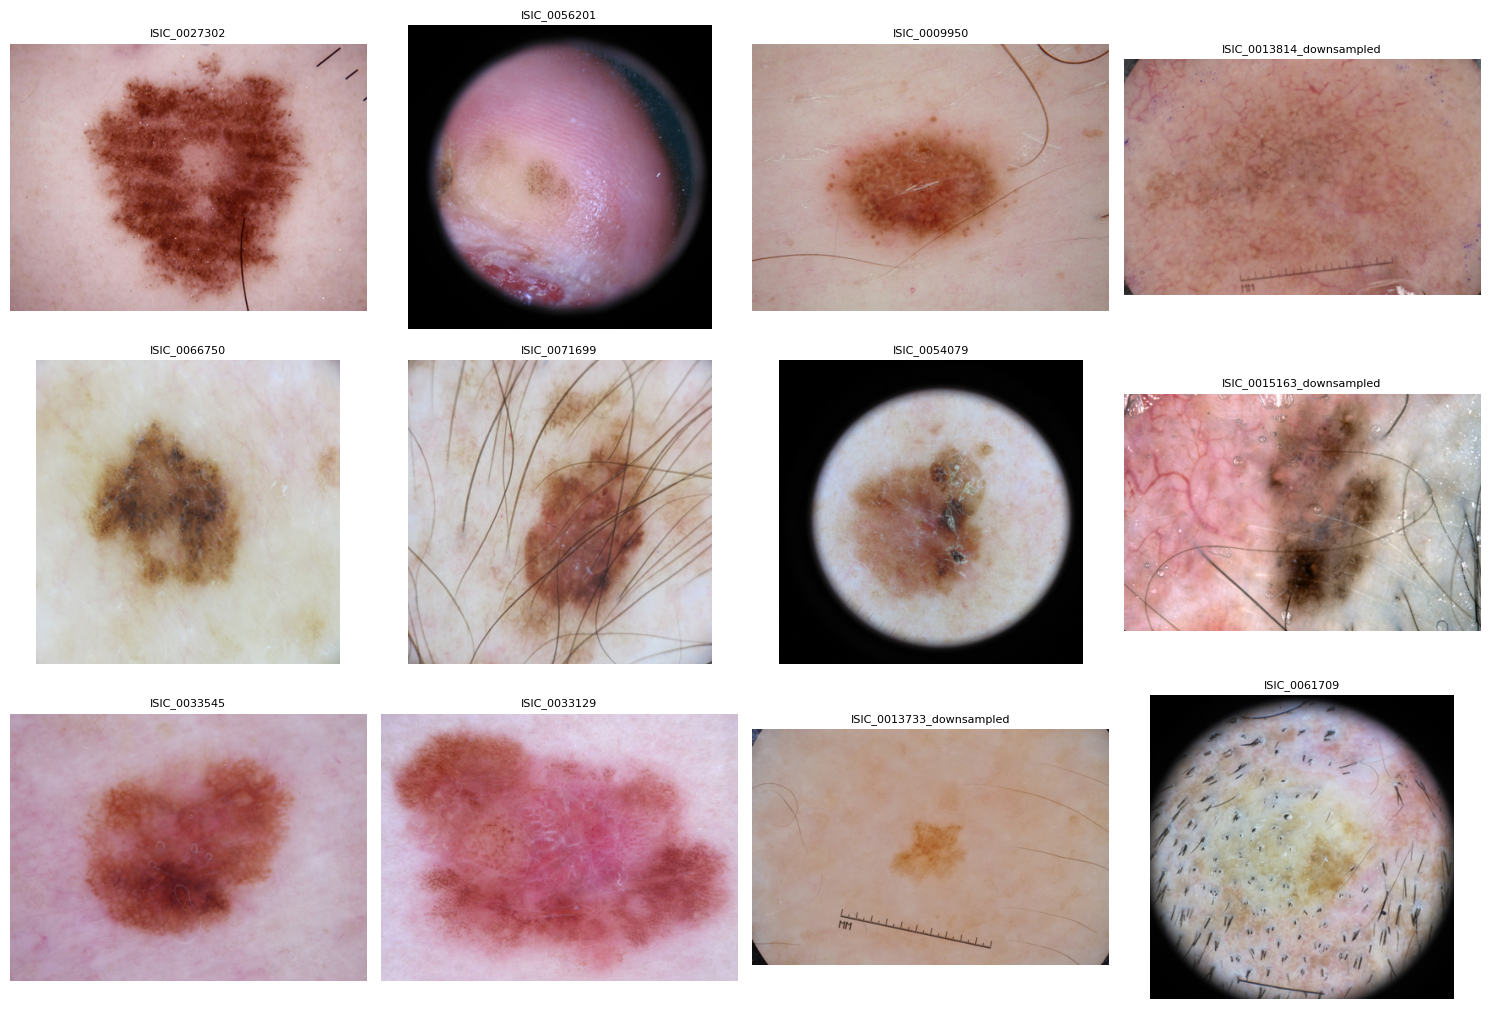

494 ảnh | trang 1/42. Hiện trên sheet chưa tính là đã xem.


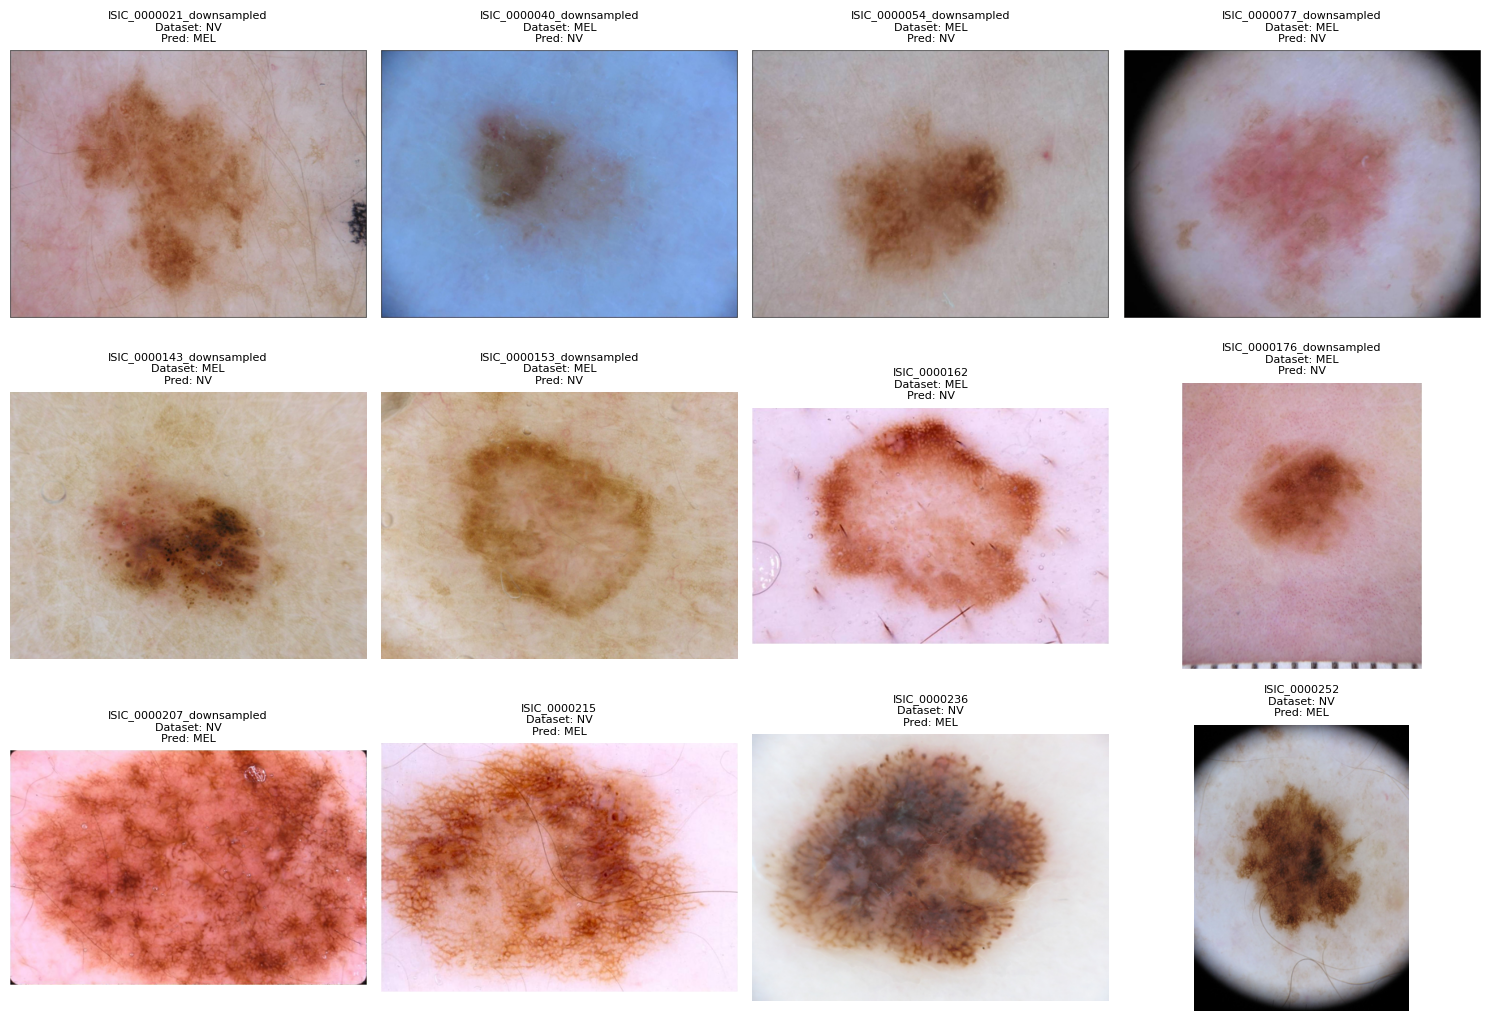

75 ảnh | trang 1/7. Hiện trên sheet chưa tính là đã xem.
Đã xuất D:\ISIC2019_Review\output\sheet_val_ALL_errors_BCC-BKL_id_0001.png


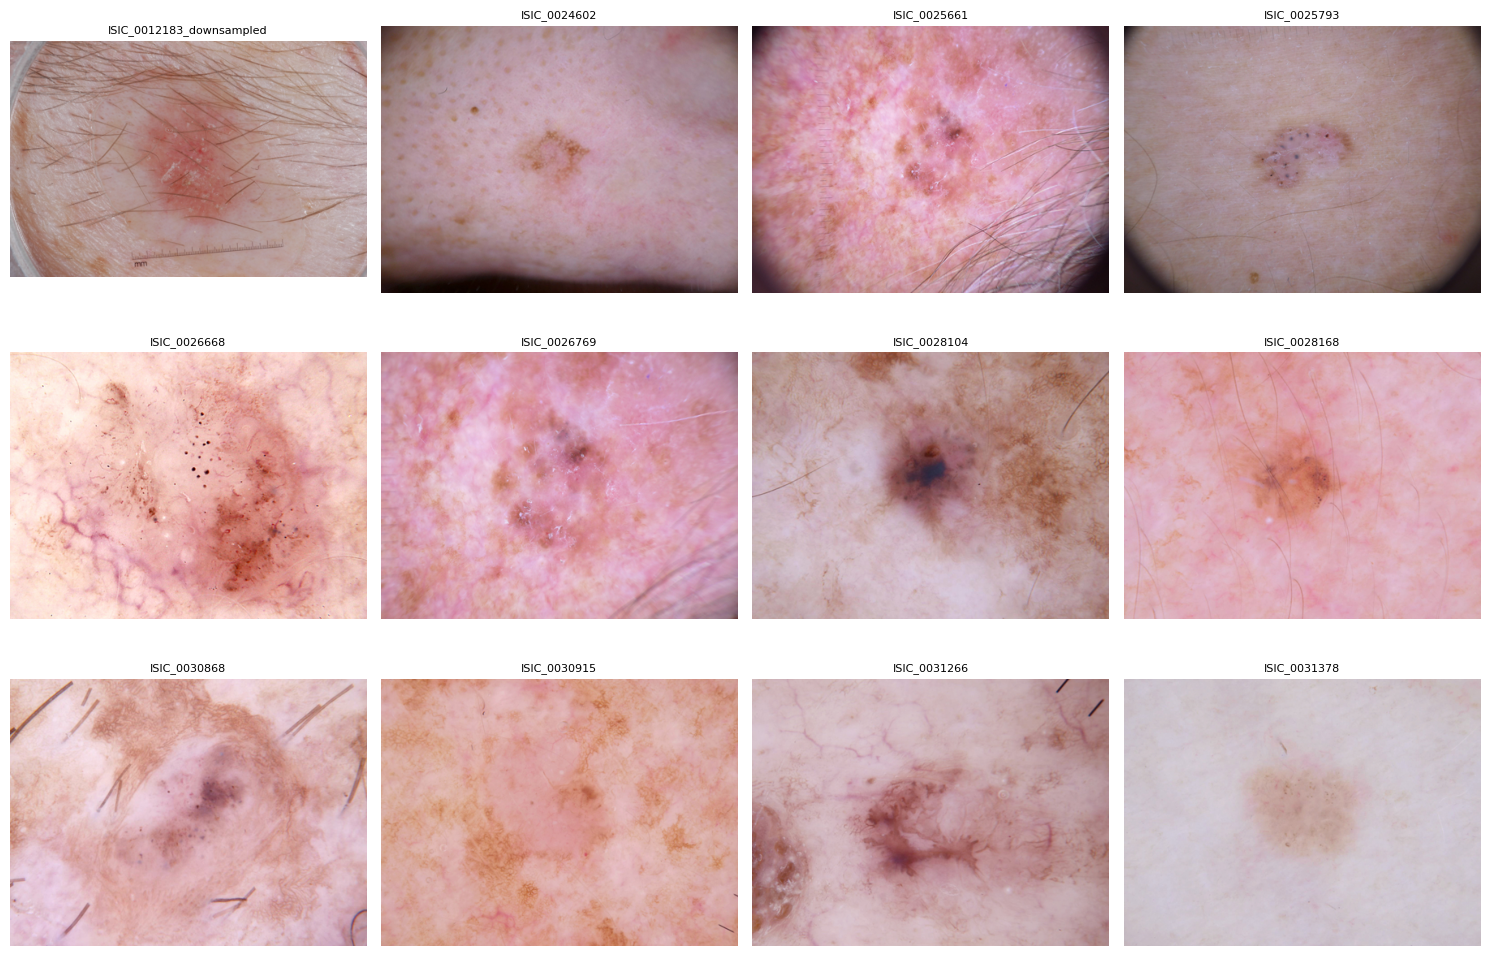

ISIC_0059443 | split: val | kích thước: 1024 x 1024



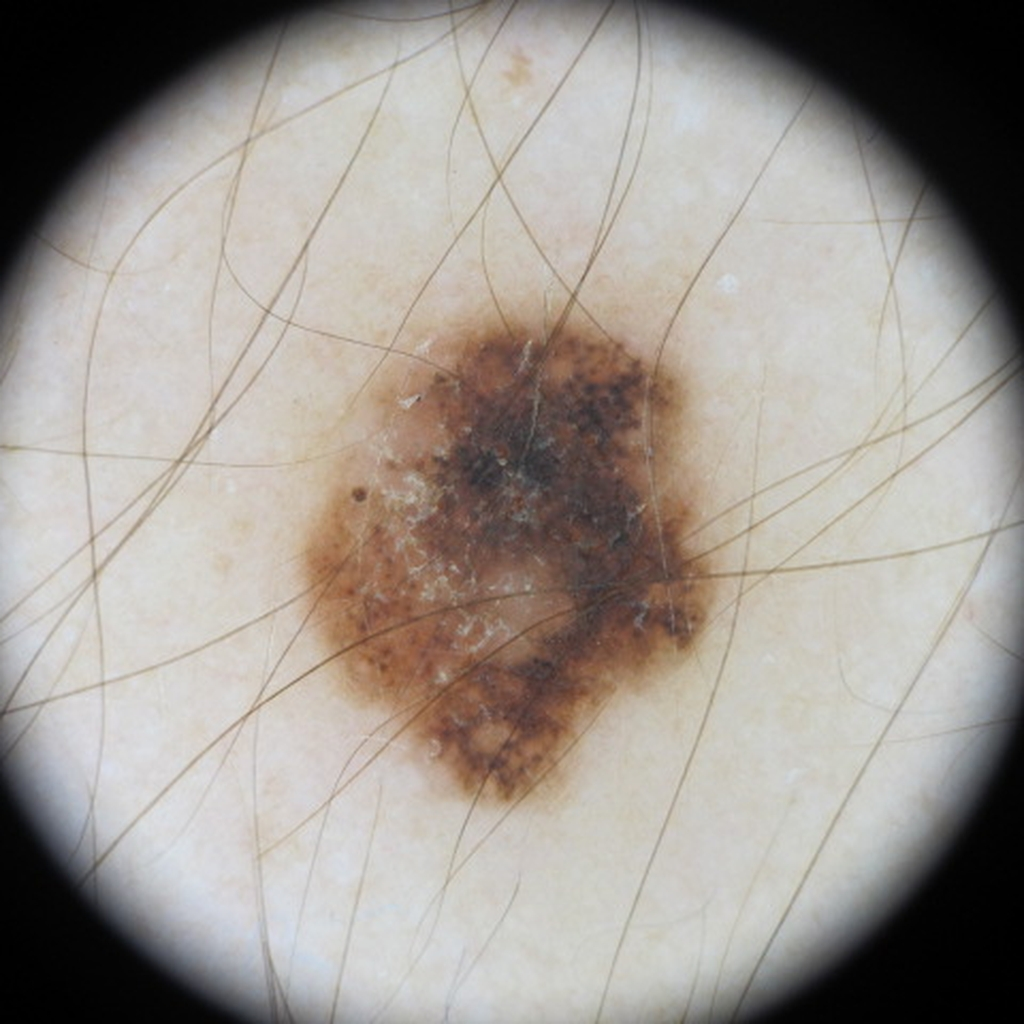

D:\ISIC2019_Review\output\opened_originals\ISIC_0059443.jpg

Đã lưu ISIC_0059443 reviewed
Đã quét 250 / 20242
Đã quét 500 / 20242
Đã quét 750 / 20242
Đã quét 1000 / 20242
Đã quét 1250 / 20242
Đã quét 1500 / 20242
Đã quét 1750 / 20242
Đã quét 2000 / 20242
Đã quét 2250 / 20242
Đã quét 2500 / 20242
Đã quét 2750 / 20242
Đã quét 3000 / 20242
Đã quét 3250 / 20242
Đã quét 3500 / 20242
Đã quét 3750 / 20242
Đã quét 4000 / 20242
Đã quét 4250 / 20242
Đã quét 4500 / 20242
Đã quét 4750 / 20242
Đã quét 5000 / 20242
Đã quét 5250 / 20242
Đã quét 5500 / 20242
Đã quét 5750 / 20242
Đã quét 6000 / 20242
Đã quét 6250 / 20242
Đã quét 6500 / 20242
Đã quét 6750 / 20242
Đã quét 7000 / 20242
Đã quét 7250 / 20242
Đã quét 7500 / 20242
Đã quét 7750 / 20242
Đã quét 8000 / 20242
Đã quét 8250 / 20242
Đã quét 8500 / 20242
Đã quét 8750 / 20242
Đã quét 9000 / 20242
Đã quét 9250 / 20242
Đã quét 9500 / 20242
Đã quét 9750 / 20242
Đã quét 10000 / 20242
Đã quét 10250 / 20242
Đã quét 10500 / 20242
Đã quét 10750 / 20242
Đã quét 11000 / 20242
Đã quét 11250 / 20242
Đã quét 11500 / 20242
Đ

,split,label_name,total,reviewed,needs_expert,remaining,percent_reviewed
0,train,AK,493,0,0,493,0.000000
1,train,BCC,2006,0,0,2006,0.000000
2,train,BKL,1573,0,0,1573,0.000000
3,train,DF,152,0,0,152,0.000000
4,train,MEL,2721,0,0,2721,0.000000
5,train,NV,7689,0,0,7689,0.000000
6,train,SCC,345,0,0,345,0.000000
7,train,VASC,161,0,0,161,0.000000
8,val,AK,200,0,0,200,0.000000
9,val,BCC,634,0,0,634,0.000000


,split,label_name,total,reviewed,needs_expert,remaining,percent_reviewed
0,train,AK,493,0,0,493,0.000000
1,train,BCC,2006,0,0,2006,0.000000
2,train,BKL,1573,0,0,1573,0.000000
3,train,DF,152,0,0,152,0.000000
4,train,MEL,2721,0,0,2721,0.000000
5,train,NV,7689,0,0,7689,0.000000
6,train,SCC,345,0,0,345,0.000000
7,train,VASC,161,0,0,161,0.000000
8,val,AK,200,0,0,200,0.000000
9,val,BCC,634,0,0,634,0.000000


In [16]:
# Cell 6: cách dùng bằng lệnh; bỏ dấu # từng lệnh muốn chạy.
contact_sheet(split='val', label='MEL', page=1, mode='all', order='random')
contact_sheet(split='val', pair='MEL-NV', mode='errors', page=1, show_label=True, show_prediction=True)
contact_sheet(split='val', pair='BCC-BKL', mode='errors', page=1, save=True)
open_original('ISIC_0059443')
save_review('ISIC_0059443', status='reviewed', hair='present', black_border='present',
             observations='Ghi điều nhìn thấy sau khi tự mở ảnh gốc.',
             hypothesis='Ghi riêng giả thuyết cần thử; không suy ra nguyên nhân từ một ảnh.')
scan_quality()  # chỉ số tự động chỉ dùng xếp hàng xem
progress()


## 7. Xuất và sao lưu kết quả sau khi quan sát

In [ ]:
# Cell 7: chạy cuối mỗi phiên, SAU KHI tương tác và lưu ghi chú
progress()
# coverage_all.csv giúp biết mọi ảnh train/val nào chưa xem; test chỉ xuất nếu đã chủ động mở.
base=catalog[['image','split','label_name','file_sha256']].reset_index(drop=True)
all_notes=base.merge(review.drop(columns=['split','label_name','file_sha256']),on='image',how='left',validate='one_to_one')
all_notes['status']=all_notes.status.fillna('unreviewed');atomic_csv(all_notes,OUT/'coverage_all.csv')
config={'schema':SCHEMA,'reviewer':REVIEWER,'prediction_run':PREDICTION_RUN,'include_test':INCLUDE_TEST,'method_frozen_note':METHOD_FROZEN_NOTE,'split_fingerprints':EXPECTED,'created_utc':utc(),'images_available':len(catalog),'note':'Hiện thumbnail/mở ảnh không đồng nghĩa đã review; reviewed cần xác nhận và ghi chú.'}
(OUT/'review_session.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
# ZIP chỉ chứa nhật ký/báo cáo/sheet; không gộp ảnh gốc để tránh file rất lớn.
import zipfile
zip_path=OUT.parent/(OUT.name+'_logs.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        if p.is_file():z.write(p,p.name)
print('Sau khi duyệt, nhớ CHẠY LẠI cell này để ZIP chứa ghi chú mới nhất.')
display(FileLink(str(zip_path)))


## 8. Tự động duyệt và gắn thẻ dị vật (Automated Artifact Tagging — Khỏi cần tick tay)

Thuật toán tự động hóa hoàn toàn quy trình duyệt dữ liệu bằng Thị giác máy tính (Computer Vision) đa tiến trình:
- **black_border**: Quét viền ngoài và 4 góc ảnh phát hiện ống soi dermatoscope tròn / góc đen.
- **hair**: Biến đổi hình thái Black-hat + phân tích chiều dài sợi để phát hiện lông/tóc che khuất.
- **ink_or_text**: Lọc dải màu độ bão hòa cao trong không gian HSV phát hiện mực bút dạ y tế.
- **ruler**: Biến đổi Hough Line phát hiện vạch chia độ của thước đo.
- **blur**: Đo phương sai Laplacian phát hiện ảnh mờ rung tay / out nét.
- **glare**: Phát hiện đốm lóa sáng phản chiếu do gel / đèn LED.

Toàn bộ kết quả được tự động ghi vào `review_log.csv` đúng 100% schema `isic_review_v1`, tự động đánh dấu `status='reviewed'`.


In [ ]:
# Cell 8: Chạy quét tự động toàn bộ ảnh bằng đa luồng CPU (Chỉ mất ~30 giây cho 5.102 ảnh)
import cv2, concurrent.futures
from tqdm.auto import tqdm

def scan_single_image(args):
    iid, img_path, split, label, file_sha, pred_label, pred_run = args
    try:
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            return None
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        
        # 1. Viền đen ống soi (black_border)
        border_px = int(min(h, w) * 0.06)
        corners = [
            gray[:border_px, :border_px],
            gray[:border_px, -border_px:],
            gray[-border_px:, :border_px],
            gray[-border_px:, -border_px:]
        ]
        corner_dark_ratio = float(np.mean([np.mean(c < 25) for c in corners]))
        has_black_border = corner_dark_ratio > 0.30
        
        # 2. Lông/tóc (hair)
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
        blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
        _, hair_thresh = cv2.threshold(blackhat, 22, 255, cv2.THRESH_BINARY)
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(hair_thresh)
        hair_pixels = sum(stats[i, cv2.CC_STAT_AREA] for i in range(1, num_labels)
                          if stats[i, cv2.CC_STAT_AREA] >= 30 and 
                          max(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]) >= 20 and 
                          (max(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]) / max(1, min(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT])) > 2.0))
        has_hair = (hair_pixels / (h * w)) > 0.001

        # 3. Mực bút dạ (ink_or_text)
        hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
        blue_purple = cv2.inRange(hsv, np.array([95, 70, 40]), np.array([160, 255, 255]))
        red_ink = cv2.inRange(hsv, np.array([170, 150, 80]), np.array([180, 255, 255]))
        ink_mask = cv2.bitwise_or(blue_purple, red_ink)
        has_ink = int(cv2.countNonZero(ink_mask)) > 200

        # 4. Thước đo (ruler)
        edges = cv2.Canny(gray, 50, 150)
        lines = cv2.HoughLinesP(edges, 1, np.pi/180, 50, minLineLength=int(min(h, w)*0.2), maxLineGap=8)
        has_ruler = (lines is not None and len(lines) >= 8)

        # 5. Ảnh mờ (blur)
        lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        has_blur = lap_var < 15.0

        # 6. Lóa sáng (glare)
        glare_mask = gray > 248
        has_glare = (cv2.countNonZero(glare_mask) / (h * w)) > 0.008

        # Tổng hợp ghi chú tự động chuẩn schema
        detected = []
        if has_hair: detected.append('hair')
        if has_black_border: detected.append('black_border')
        if has_ink: detected.append('ink_mark')
        if has_ruler: detected.append('ruler')
        if has_blur: detected.append('blur')
        if has_glare: detected.append('glare')
        
        obs_text = "Tự động phát hiện: " + (", ".join(detected) if detected else "ảnh sạch (không dị vật lớn)")
        hyp_text = "Khắc phục triệt để bởi Phương án 10: " + ("+ ".join(detected) if detected else "chuẩn hóa màu sắc")
        
        return {
            'schema': SCHEMA,
            'image': iid,
            'split': split,
            'label_name': label,
            'file_sha256': file_sha,
            'status': 'reviewed',
            'reviewer': REVIEWER,
            'updated_utc': utc(),
            'prediction_run': pred_run or '',
            'hair': 'present' if has_hair else 'absent',
            'ruler': 'present' if has_ruler else 'absent',
            'black_border': 'present' if has_black_border else 'absent',
            'ink_or_text': 'present' if has_ink else 'absent',
            'blur': 'present' if has_blur else 'absent',
            'glare': 'present' if has_glare else 'absent',
            'uneven_light': 'absent',
            'edge_cut': 'absent',
            'apparent_skin_color': '',
            'lesion_fraction': '',
            'morphology': '',
            'colors': '',
            'border': '',
            'structures': '',
            'typicality': 'typical_candidate' if not detected else 'unknown',
            'observations': obs_text,
            'hypothesis': hyp_text,
            'expert_question': ''
        }
    except Exception as e:
        return None

def auto_scan_dataset(target_split='val', max_workers=12):
    global review
    sub_cat = catalog if target_split == 'all' else catalog[catalog.split == target_split]
    print(f"🚀 Bắt đầu quét tự động {len(sub_cat)} ảnh ({target_split}) bằng {max_workers} luồng CPU...")
    
    tasks = []
    for iid, row in sub_cat.iterrows():
        tasks.append((
            iid, str(row['path']), row['split'], row['label_name'],
            row['file_sha256'], row.get('pred_label', ''), row.get('prediction_run', '')
        ))
    
    results = []
    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        for res in tqdm(executor.map(scan_single_image, tasks), total=len(tasks), desc="Quét tự động"):
            if res is not None:
                results.append(res)
                
    df_new = pd.DataFrame(results)
    review = pd.concat([review[~review.image.isin(df_new.image)], df_new], ignore_index=True)
    atomic_csv(review[REVIEW_COLS], LOG)
    atomic_csv(review[REVIEW_COLS], OUT / 'review_log.csv')
    print(f"✅ Hoàn thành quét tự động {len(df_new)} ảnh! Tiến độ đã cập nhật vào {LOG}")
    return df_new

# Thực hiện quét tự động tập Validation
auto_scan_results = auto_scan_dataset(target_split='val', max_workers=12)
progress()


## 9. Phân tích lỗi mô hình tự động & Bằng chứng định lượng (Error Analysis & Quantitative Evidence)

Đối chiếu kết quả quét dị vật với kết quả dự đoán của mô hình ResNet-18 trên tập Validation:
- Đánh giá xem sự xuất hiện của từng loại dị vật làm tăng **Tỷ lệ dự đoán sai (Error Rate)** bao nhiêu %.
- Cung cấp số liệu định lượng làm cơ sở khoa học để thiết kế **Phương án 10: Full Pipeline nâng cao**.


In [ ]:
# Cell 9: Tự động phân tích nguyên nhân mô hình đoán sai & Vẽ biểu đồ bằng chứng khoa học
import seaborn as sns

# Kết hợp bảng review tự động với dự đoán validation
val_df = catalog[catalog.split == 'val'].reset_index(drop=True).copy()
merged = val_df.merge(review[['image', 'hair', 'black_border', 'ink_or_text', 'ruler', 'blur', 'glare']], on='image', how='inner')
merged['is_error'] = merged['label_name'] != merged['pred_label']

overall_error = merged['is_error'].mean() * 100
print(f"📊 TỔNG QUAN TẬP VALIDATION ({len(merged)} ảnh):")
print(f"   - Tỷ lệ lỗi dự đoán chung của ResNet-18: {overall_error:.2f}% (Accuracy: {100-overall_error:.2f}%)")

artifact_cols = ['hair', 'black_border', 'ink_or_text', 'blur', 'glare']
stats = []

for art in artifact_cols:
    present_mask = merged[art] == 'present'
    n_present = present_mask.sum()
    pct_dataset = (n_present / len(merged)) * 100
    
    err_present = merged[present_mask]['is_error'].mean() * 100 if n_present > 0 else 0
    err_absent = merged[~present_mask]['is_error'].mean() * 100
    risk_diff = err_present - err_absent
    
    stats.append({
        'Dị vật (Artifact)': art,
        'Số lượng (ảnh)': n_present,
        'Tỷ lệ trong dataset (%)': round(pct_dataset, 1),
        'Lỗi khi CÓ dị vật (%)': round(err_present, 1),
        'Lỗi khi KHÔNG CÓ dị vật (%)': round(err_absent, 1),
        'Mức tăng lỗi (+%)': round(risk_diff, 1)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

# Vẽ biểu đồ trực quan hóa
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Biểu đồ tỷ lệ dị vật
sns.barplot(data=stats_df, x='Dị vật (Artifact)', y='Tỷ lệ trong dataset (%)', palette='Blues_r', ax=axes[0])
axes[0].set_title("Tỷ lệ phân bố các loại dị vật trong ISIC 2019 Val", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Tỷ lệ (%)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10)

# 2. Biểu đồ so sánh tỷ lệ lỗi khi có vs không có dị vật
plot_df = stats_df.melt(id_vars='Dị vật (Artifact)', value_vars=['Lỗi khi KHÔNG CÓ dị vật (%)', 'Lỗi khi CÓ dị vật (%)'], 
                        var_name='Trạng thái', value_name='Tỷ lệ lỗi (%)')
sns.barplot(data=plot_df, x='Dị vật (Artifact)', y='Tỷ lệ lỗi (%)', hue='Trạng thái', palette=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title("Tác động của dị vật lên tỷ lệ dự đoán sai của ResNet-18", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Tỷ lệ lỗi (%)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=9)

plt.tight_layout()
fig_path = OUT / 'artifact_impact_analysis.png'
fig.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ phân tích lỗi tại: {fig_path}")


## 10. Triển khai Phương án 10: Full Preprocessing Pipeline nâng cao

**Quy trình 5 công đoạn liên hoàn:**
1. **Auto-Crop viền**: Tự động phát hiện vùng da trung tâm và cắt bỏ khung đen / viền ống soi dermatoscope.
2. **DullRazor (Xóa lông)**: Morphological Black-hat filter trích xuất mask sợi lông $
ightarrow$ Inpainting phục hồi kết cấu da tự nhiên.
3. **Xóa mực bút dạ**: Tách dải màu bão hòa cao của mực y tế (xanh dương, tím gentian, đỏ đậm) trong hệ màu HSV $
ightarrow$ Inpainting.
4. **Shades of Gray ($p=6$)**: Chuẩn hóa nhiệt độ màu / nguồn sáng theo chuẩn Minkowski norm tối ưu trong da liễu.
5. **Nhẹ CLAHE**: Tăng cường tương phản cục bộ một cách nhẹ nhàng trên kênh Luminance (L trong không gian LAB) để làm rõ cấu trúc mạng sắc tố mà không làm biến đổi màu bệnh lý.


In [ ]:
# Cell 10: Cài đặt hoàn chỉnh Phương án 10 & Trực quan hóa Before/After từng bước
def pipeline_10_full(img_rgb, return_steps=False):
    steps = {'0_original': img_rgb.copy()}
    
    # --- Bước 1: Auto-Crop viền đen / ống soi tròn ---
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 25, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    h, w = img_rgb.shape[:2]
    if contours:
        c = max(contours, key=cv2.contourArea)
        x, y, cw, ch = cv2.boundingRect(c)
        if cw * ch < 0.95 * w * h and cw > 0.5 * w and ch > 0.5 * h:
            img_rgb = img_rgb[y:y+ch, x:x+cw]
            h, w = img_rgb.shape[:2]
    steps['1_autocrop'] = img_rgb.copy()

    # --- Bước 2: DullRazor (Khử lông) ---
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_thresh = cv2.threshold(blackhat, 14, 255, cv2.THRESH_BINARY)
    hair_mask = cv2.medianBlur(hair_thresh, 3)
    if cv2.countNonZero(hair_mask) > 50:
        img_rgb = cv2.inpaint(img_rgb, hair_mask, 3, cv2.INPAINT_TELEA)
    steps['2_dullrazor'] = img_rgb.copy()

    # --- Bước 3: Xóa vết mực bút dạ y tế ---
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    blue_purple = cv2.inRange(hsv, np.array([90, 60, 40]), np.array([160, 255, 255]))
    red_ink = cv2.inRange(hsv, np.array([0, 180, 120]), np.array([10, 255, 255]))
    ink_mask = cv2.bitwise_or(blue_purple, red_ink)
    if cv2.countNonZero(ink_mask) > 100:
        img_rgb = cv2.inpaint(img_rgb, ink_mask, 3, cv2.INPAINT_TELEA)
    steps['3_ink_removed'] = img_rgb.copy()

    # --- Bước 4: Shades of Gray (Minkowski p=6) ---
    p = 6
    img_float = img_rgb.astype(np.float32)
    e = np.power(np.mean(np.power(img_float, p), axis=(0, 1)), 1.0 / p)
    norm = np.mean(e)
    if np.all(e > 0):
        scale = norm / e
        img_float = np.clip(img_float * scale, 0, 255)
        img_rgb = img_float.astype(np.uint8)
    steps['4_shades_of_gray'] = img_rgb.copy()

    # --- Bước 5: Nhẹ CLAHE trên kênh L (LAB space) ---
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge((l_eq, a, b))
    final_result = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)
    steps['5_pipeline10_final'] = final_result

    if return_steps:
        return steps
    return final_result

def visualize_pipeline_demonstration(sample_images=None):
    if sample_images is None:
        hair_imgs = review[review.hair == 'present']['image'].head(1).tolist()
        border_imgs = review[review.black_border == 'present']['image'].head(1).tolist()
        sample_images = hair_imgs + border_imgs
        if len(sample_images) < 3:
            sample_images += catalog[catalog.split == 'val']['image'].head(3 - len(sample_images)).tolist()
            
    for iid in sample_images:
        row = catalog.loc[iid]
        img_orig = np.array(Image.open(row['path']).convert('RGB'))
        steps = pipeline_10_full(img_orig, return_steps=True)
        
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))
        step_titles = [
            ("Gốc (Original)", '0_original'),
            ("1. Auto-Crop viền", '1_autocrop'),
            ("2. DullRazor (Khử lông)", '2_dullrazor'),
            ("3. Shades of Gray", '4_shades_of_gray'),
            ("★ Phương án 10 Hoàn chỉnh", '5_pipeline10_final')
        ]
        
        for ax, (title, key) in zip(axes, step_titles):
            ax.imshow(steps[key])
            ax.set_title(title, fontsize=11, fontweight='bold' if 'Phương án 10' in title else 'normal')
            ax.axis('off')
            
        plt.suptitle(f"Tiền xử lý Phương án 10 — ID: {iid} | Lớp: {row['label_name']}", fontsize=14, y=1.03)
        plt.tight_layout()
        plt.show()

# Chạy demo trực quan hóa trên các ảnh thực tế
visualize_pipeline_demonstration()
